In [6]:

# 1. Import required libraries for Rice Leaf Detection

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Set seed for reproducible results
keras.utils.set_random_seed(42)
tf.random.set_seed(42)

# Check library versions
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("NumPy version:", np.__version__)


TensorFlow version: 2.22.0-rc0
Keras version: 3.15.1
NumPy version: 2.5.3


In [7]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\Welcome\OneDrive\Desktop\DL Project
['archive', 'archive.rice', 'class_names.json', 'dl_env', 'Drowsiness_Detection_Live.ipynb', 'Emotion_Detection_CNN.ipynb', 'emotion_model.keras', 'face_landmarker.task', 'requirements.txt', 'rice_leaf_cnn.keras', 'Rice_Leaf_Disease_Detection_Using_CNN.ipynb']


In [8]:
import os

dataset_path = os.path.abspath("archive.rice")

print("Dataset Path:", dataset_path)
print("Folders:", os.listdir(dataset_path))

Dataset Path: c:\Users\Welcome\OneDrive\Desktop\DL Project\archive.rice
Folders: ['Rice_Leaf_AUG']


In [9]:
import os

dataset_path = os.path.abspath(
    os.path.join("archive.rice", "Rice_Leaf_AUG")
)

print("Correct Dataset Path:", dataset_path)
print("Folders Inside Dataset:")

for item in os.listdir(dataset_path):
    if os.path.isdir(os.path.join(dataset_path, item)):
        print(item)

Correct Dataset Path: c:\Users\Welcome\OneDrive\Desktop\DL Project\archive.rice\Rice_Leaf_AUG
Folders Inside Dataset:
Bacterial Leaf Blight
Brown Spot
Healthy Rice Leaf
Leaf Blast
Leaf scald
Sheath Blight


In [10]:
IMG_SIZE = (224, 224)  # Sabhi images ka size same rakha
BATCH_SIZE = 32        # Ek baar mein 32 images process hongi
SEED = 42              # Same random split maintain karne ke liye

# 80% data training ke liye
train_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.20,  # 20% data validation ke liye
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"  # Har disease class ko integer label milega
)

# 20% data model validation ke liye
val_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_data.class_names  # Disease classes ke naam
num_classes = len(class_names)       # Total disease classes

print("Classes:", class_names)
print("Total Classes:", num_classes)

Found 3829 files belonging to 6 classes.
Using 3064 files for training.
Found 3829 files belonging to 6 classes.
Using 765 files for validation.
Classes: ['Bacterial Leaf Blight', 'Brown Spot', 'Healthy Rice Leaf', 'Leaf Blast', 'Leaf scald', 'Sheath Blight']
Total Classes: 6


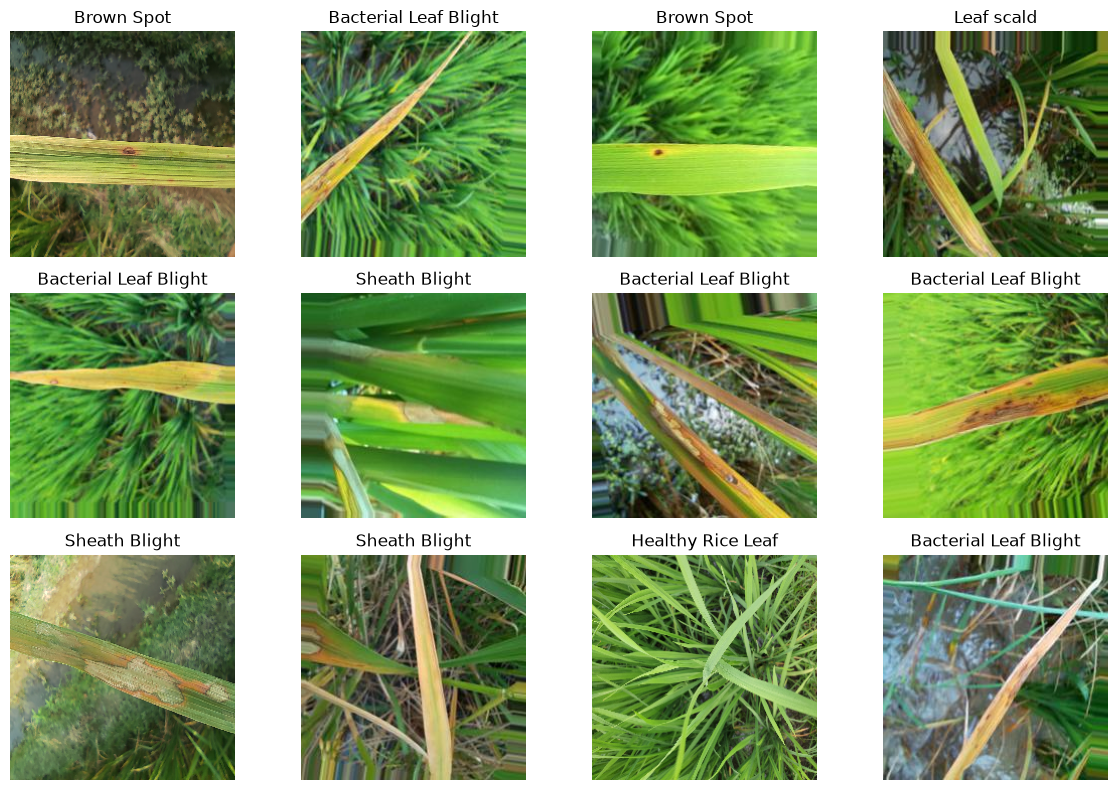

In [11]:
plt.figure(figsize=(12, 8))  # Images display karne ke liye figure size

for images, labels in train_data.take(1):  # Training data ka ek batch liya
    for i in range(min(12, len(images))):  # Maximum 12 images show hongi
        plt.subplot(3, 4, i + 1)  # 3 rows aur 4 columns ka layout

        plt.imshow(tf.cast(images[i], tf.uint8).numpy())  # Image display ki
        plt.title(class_names[int(labels[i].numpy())])  # Disease ka naam show kiya
        plt.axis("off")  # Axis hide ki

plt.tight_layout()  # Images ke beech proper spacing
plt.show()  # Final output display kiya

In [12]:
for images, labels in train_data.take(1):  # Training data ka ek batch liya
    print("Batch Shape:", images.shape)  # Total images aur unka size check kiya
    print("Single Image Shape:", images[0].shape)  # Ek image ka shape check kiya
    print("Minimum Pixel:", tf.reduce_min(images).numpy())  # Minimum pixel value
    print("Maximum Pixel:", tf.reduce_max(images).numpy())  # Maximum pixel value

Batch Shape: (32, 224, 224, 3)
Single Image Shape: (224, 224, 3)
Minimum Pixel: 0.0
Maximum Pixel: 255.0


In [13]:

def normalize_images(images, labels):
    images = tf.cast(images, tf.float32)  # Images ko float format mein convert kiya
    images = images / 255.0  # Pixel values 0-255 se 0-1 range mein laayi

    return images, labels  # Normalized images aur unke labels return kiye

train_normalized = train_data.map(normalize_images)  # Training images normalize ki
val_normalized = val_data.map(normalize_images)  # Validation images normalize ki

print("Normalization Complete!")  # Process complete hone ka message


Normalization Complete!


In [14]:

for images, labels in train_normalized.take(1):  # Training dataset ki ek batch li
    print("Normalized Shape:", images.shape)  # Images ka shape check kiya
    print("Minimum Pixel:", tf.reduce_min(images).numpy())  # Sabse chhoti pixel value check ki
    print("Maximum Pixel:", tf.reduce_max(images).numpy())  # Sabse badi pixel value check ki


Normalized Shape: (32, 224, 224, 3)
Minimum Pixel: 0.0
Maximum Pixel: 1.0


In [15]:
model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # CNN Block 1
    layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu",
        name="conv1"
    ),
    layers.MaxPooling2D((2, 2)),

    # CNN Block 2
    layers.Conv2D(
        64, (3, 3),
        padding="same",
        activation="relu",
        name="conv2"
    ),
    layers.MaxPooling2D((2, 2)),

    # CNN Block 3
    layers.Conv2D(
        128, (3, 3),
        padding="same",
        activation="relu",
        name="conv3"
    ),
    layers.MaxPooling2D((2, 2)),

    # CNN Block 4
    layers.Conv2D(
        256, (3, 3),
        padding="same",
        activation="relu",
        name="feature_extraction"
    ),
    layers.MaxPooling2D((2, 2)),

    # Feature maps to feature vector
    layers.GlobalAveragePooling2D(name="global_average_pooling"),

    # Dense classification layer
    layers.Dense(128, activation="relu", name="dense_layer"),

    layers.Dropout(0.4),

    # Six disease class probabilities
    layers.Dense(num_classes, activation="softmax", name="softmax_output")
])

print("CNN Model Created!")
model.summary()

CNN Model Created!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_extraction (Conv2D)     │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_layer (Dense)             │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_output (Dense)          │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 422,086 (1.61 MB)

 Trainable params: 422,086 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:

for images, labels in train_normalized.take(1):  # Training dataset se ek batch li
    sample = images[:1]  # Sirf ek image select ki

    model(sample, training=False)  # Model ko initialize karke input shape define ki

    feature_model = keras.Model(
        inputs=model.inputs,
        outputs=model.get_layer("feature_extraction").output  # Feature extraction layer ka output liya
    )

    feature_maps = feature_model(sample, training=False).numpy()  # Image ke extracted features nikale

    print("Original Image Shape:", images[0].shape)  # Original image ka shape check kiya
    print("Feature Maps Shape:", feature_maps.shape)  # Extracted feature maps ka shape check kiya


Original Image Shape: (224, 224, 3)
Feature Maps Shape: (1, 28, 28, 256)


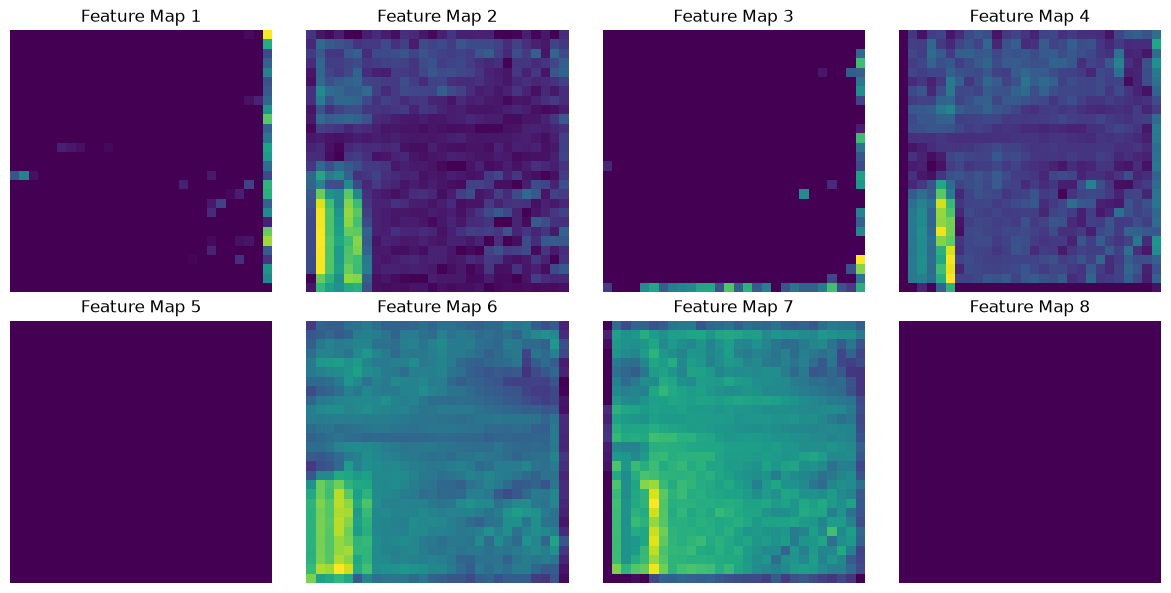

In [21]:
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    plt.imshow(feature_maps[0, :, :, i], cmap="viridis")
    plt.title(f"Feature Map {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:

gap_model = keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("global_average_pooling").output  # GAP layer ka output lene ke liye
)

for images, labels in train_normalized.take(1):  # Training dataset se ek batch li
    gap_features = gap_model.predict(images[:1], verbose=0)  # Ek image ke GAP features nikale

    print("Before GAP:", feature_maps.shape)  # GAP se pehle feature maps ka shape
    print("After GAP:", gap_features.shape)  # GAP ke baad features ka shape


Before GAP: (1, 28, 28, 256)
After GAP: (1, 256)


In [18]:

dense_model = keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("dense_layer").output  # Dense layer ka output extract karne ke liye
)

for images, labels in train_normalized.take(1):  # Training dataset se ek batch li
    dense_features = dense_model.predict(images[:1], verbose=0)  # Ek image ke dense features nikale

    print("Dense Output Shape:", dense_features.shape)  # Dense layer ke output ka shape check kiya


Dense Output Shape: (1, 128)


In [19]:

softmax_model = keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("softmax_output").output  # Softmax layer ka output lene ke liye
)

for images, labels in train_normalized.take(1):  # Training dataset se ek batch li
    softmax_output = softmax_model.predict(images[:1], verbose=0)  # Ek image ki class probabilities nikali

    print("Softmax Output Shape:", softmax_output.shape)  # Output ka shape check kiya
    print("Class Probabilities:", softmax_output[0])  # Har class ki probability print ki
    print("Probability Sum:", np.sum(softmax_output[0]))  # Check kiya ki probabilities ka sum lagbhag 1 hai


Softmax Output Shape: (1, 6)
Class Probabilities: [0.16319257 0.16592471 0.16830403 0.16723052 0.16778466 0.16756351]
Probability Sum: 1.0000001


In [20]:

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),  # Weights update karne ke liye Adam optimizer
    loss="sparse_categorical_crossentropy",  # Integer-encoded class labels ki prediction error calculate ki
    metrics=["accuracy"]  # Training aur validation accuracy track karne ke liye
)

print("Model Compiled!")  # Model compilation complete hone ka message


Model Compiled!


In [21]:
EPOCHS = 10

history = model.fit(
    train_normalized,
    validation_data=val_normalized,
    epochs=EPOCHS
)

Epoch 1/10


c:\Users\Welcome\OneDrive\Desktop\DL Project\dl_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


96/96 ━━━━━━━━━━━━━━━━━━━━ 165s 2s/step - accuracy: 0.2396 - loss: 1.7283 - val_accuracy: 0.2471 - val_loss: 1.6617
Epoch 2/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.4148 - loss: 1.4789 - val_accuracy: 0.5333 - val_loss: 1.2762
Epoch 3/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.5020 - loss: 1.2885 - val_accuracy: 0.6026 - val_loss: 1.1623
Epoch 4/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.5333 - loss: 1.2330 - val_accuracy: 0.5307 - val_loss: 1.2594
Epoch 5/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.5483 - loss: 1.1715 - val_accuracy: 0.6183 - val_loss: 1.0706
Epoch 6/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 149s 2s/step - accuracy: 0.5809 - loss: 1.1103 - val_accuracy: 0.6052 - val_loss: 1.0739
Epoch 7/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 183s 2s/step - accuracy: 0.5950 - loss: 1.0635 - val_accuracy: 0.6288 - val_loss: 1.0317
Epoch 8/10
96/96 ━━━━━━━━━━━━━━━━━━━━ 166s 2s/step - accuracy: 0.5956 - loss: 1.0532 - val_accuracy: 0.6078 - val_loss: 0.

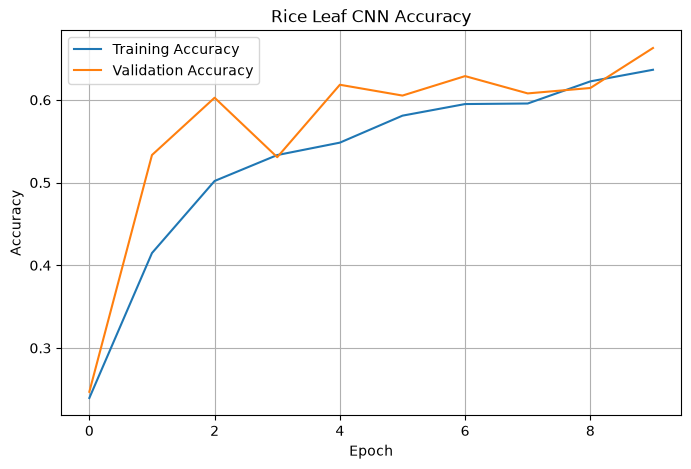

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Rice Leaf CNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

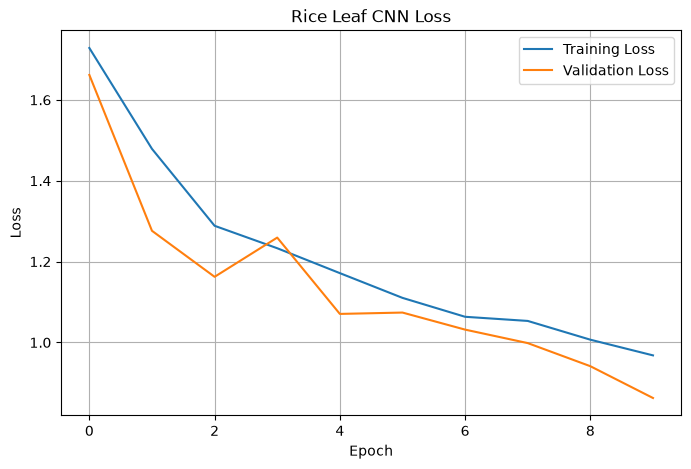

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Rice Leaf CNN Loss")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
val_loss, val_accuracy = model.evaluate(
    val_normalized,
    verbose=1
)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 9s 351ms/step - accuracy: 0.6627 - loss: 0.8626
Validation Loss: 0.8626
Validation Accuracy: 66.27%


In [25]:
model.save("rice_leaf_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [26]:
import os
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

image_folder = r"C:\Users\Welcome\Downloads\archive.rice\Rice_Leaf_AUG"
IMG_SIZE = (224, 224)

# Folder aur uske subfolders mein pehli image dhoondho
image_path = None
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")

for root, _, filenames in os.walk(image_folder):
    for filename in filenames:
        if filename.lower().endswith(valid_extensions):
            image_path = os.path.join(root, filename)
            break
    if image_path:
        break

if image_path is None:
    raise FileNotFoundError(f"Is folder mein image nahi mili: {image_folder}")

img = load_img(image_path, target_size=IMG_SIZE, color_mode="rgb")
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0

print("Loaded image:", image_path)
print("Image Shape:", img_array.shape)

Loaded image: C:\Users\Welcome\Downloads\archive.rice\Rice_Leaf_AUG\Bacterial Leaf Blight\20231006_164208.jpg
Image Shape: (1, 224, 224, 3)


In [27]:
predictions = model.predict(img_array, verbose=0)

predicted_index = np.argmax(predictions[0])
predicted_disease = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

print("Predicted Disease:", predicted_disease)
print(f"Model Confidence: {confidence:.2f}%")

Predicted Disease: Bacterial Leaf Blight
Model Confidence: 55.46%


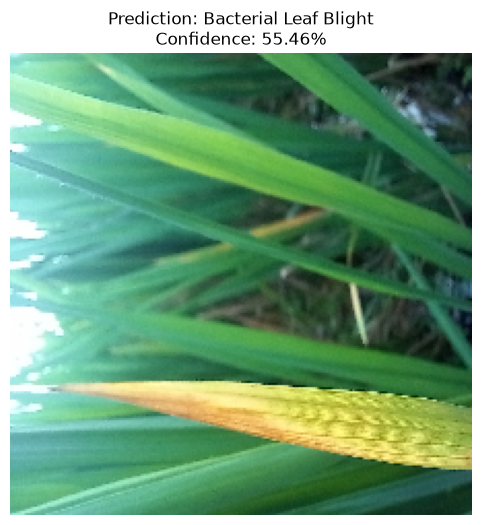

In [28]:
plt.figure(figsize=(6, 6))

plt.imshow(img)
plt.title(
    f"Prediction: {predicted_disease}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()

In [30]:
for disease, probability in sorted(
    zip(class_names, predictions[0]),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{disease}: {probability * 100:.2f}%")

Bacterial Leaf Blight: 55.46%
Leaf scald: 24.29%
Leaf Blast: 16.41%
Brown Spot: 2.10%
Sheath Blight: 1.72%
Healthy Rice Leaf: 0.02%
